# Sales Performance & Business Analytics

## Project Overview

This project analyzes sales data using Python and SQL to understand sales performance, profitability, customer behavior, product performance, and regional trends.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
df= pd.read_csv("../data/Sample - Superstore.csv",encoding="latin1")


In [5]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [6]:
df.shape

(9994, 21)

In [7]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [9]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [10]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Quantity Sold:", total_quantity)

Total Sales: 2297200.86
Total Profit: 286397.02
Total Quantity Sold: 37873


In [13]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

category_sales

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64

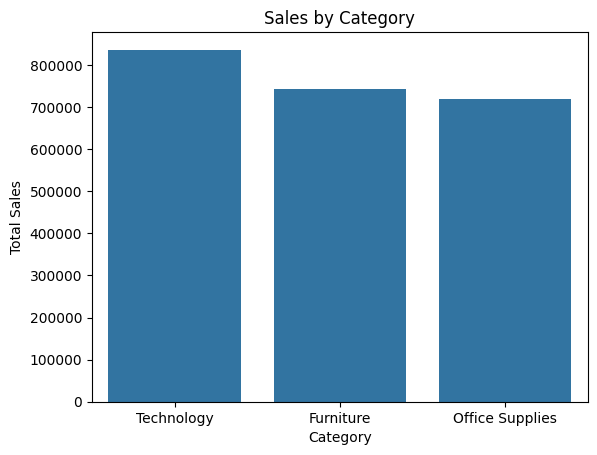

In [14]:
sns.barplot(x=category_sales.index, y=category_sales.values)

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.show()

In [15]:
category_profit = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

category_profit

Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64

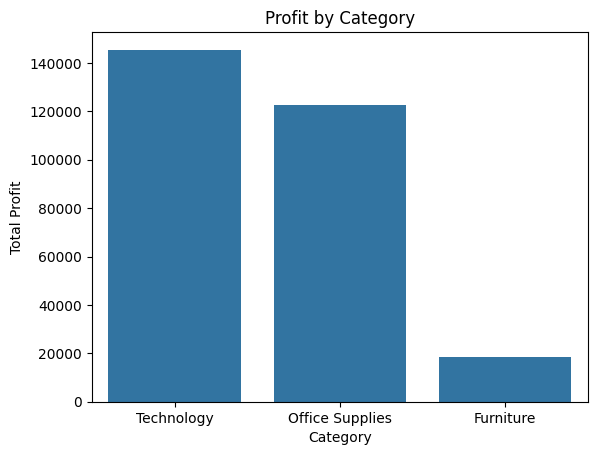

In [16]:
sns.barplot(x=category_profit.index, y=category_profit.values)

plt.title("Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.show()

In [17]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

region_sales

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64

In [18]:
region_profit = df.groupby("Region")["Profit"].sum().sort_values(ascending=False)

region_profit

Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64

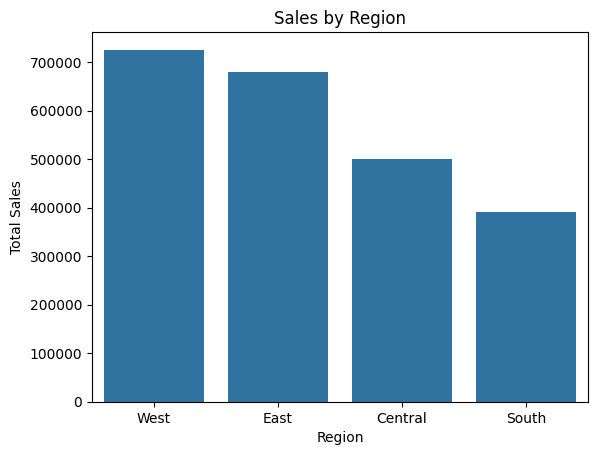

In [19]:
sns.barplot(x=region_sales.index, y=region_sales.values)

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.show()

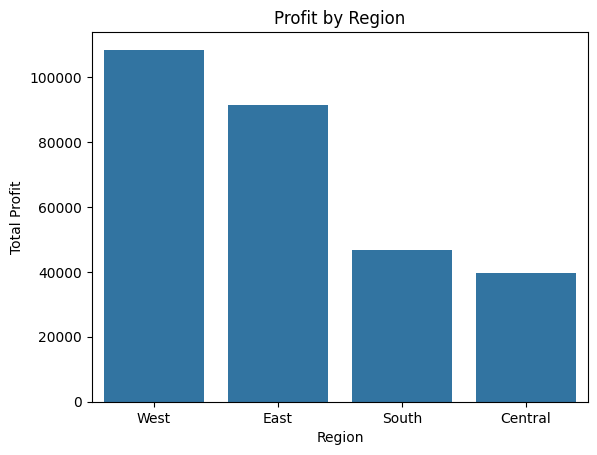

In [20]:
sns.barplot(x=region_profit.index, y=region_profit.values)

plt.title("Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.show()

In [21]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

In [22]:
monthly_sales = (
    df.groupby(df["Order Date"].dt.to_period("M"))["Sales"]
    .sum()
)

monthly_sales

Order Date
2014-01     14236.8950
2014-02      4519.8920
2014-03     55691.0090
2014-04     28295.3450
2014-05     23648.2870
2014-06     34595.1276
2014-07     33946.3930
2014-08     27909.4685
2014-09     81777.3508
2014-10     31453.3930
2014-11     78628.7167
2014-12     69545.6205
2015-01     18174.0756
2015-02     11951.4110
2015-03     38726.2520
2015-04     34195.2085
2015-05     30131.6865
2015-06     24797.2920
2015-07     28765.3250
2015-08     36898.3322
2015-09     64595.9180
2015-10     31404.9235
2015-11     75972.5635
2015-12     74919.5212
2016-01     18542.4910
2016-02     22978.8150
2016-03     51715.8750
2016-04     38750.0390
2016-05     56987.7280
2016-06     40344.5340
2016-07     39261.9630
2016-08     31115.3743
2016-09     73410.0249
2016-10     59687.7450
2016-11     79411.9658
2016-12     96999.0430
2017-01     43971.3740
2017-02     20301.1334
2017-03     58872.3528
2017-04     36521.5361
2017-05     44261.1102
2017-06     52981.7257
2017-07     45264.4160


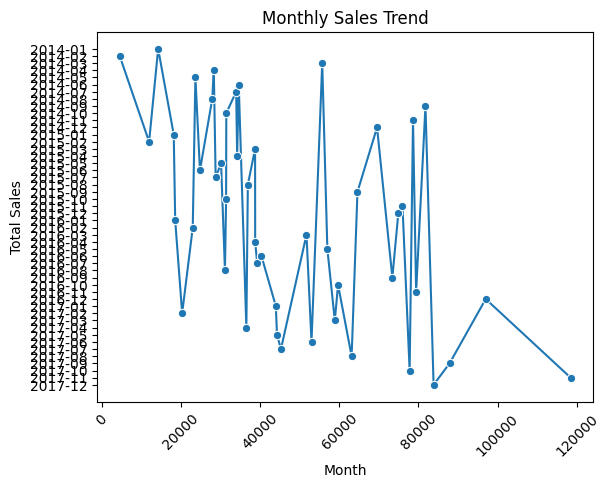

In [23]:
monthly_sales.index = monthly_sales.index.astype(str)

sns.lineplot(x=monthly_sales.values, y=monthly_sales.index, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

In [24]:
top_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64

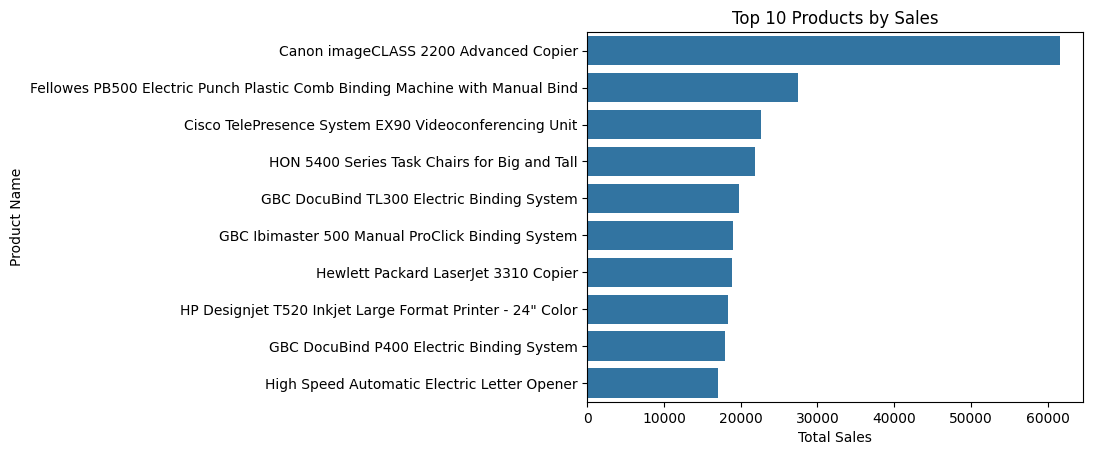

In [25]:
sns.barplot(x=top_products.values, y=top_products.index)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")
plt.show()

In [26]:
top_customers = (
    df.groupby("Customer Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64

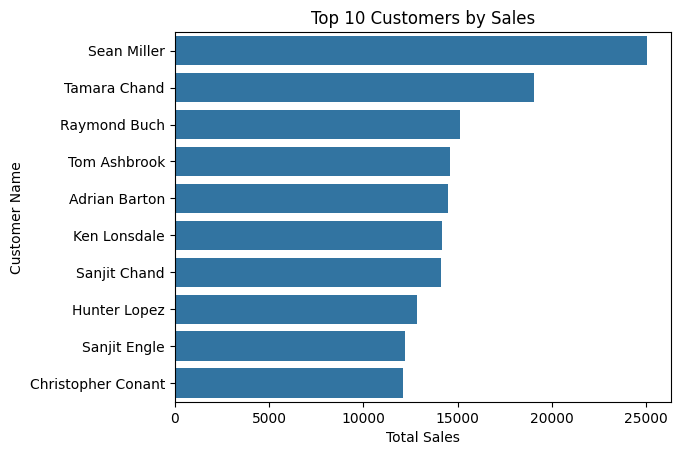

In [27]:
sns.barplot(x=top_customers.values, y=top_customers.index)

plt.title("Top 10 Customers by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer Name")
plt.show()

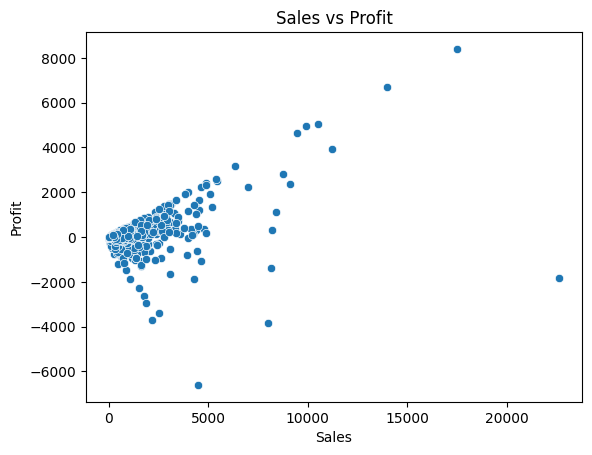

In [28]:
sns.scatterplot(data=df, x="Sales", y="Profit")

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.show()

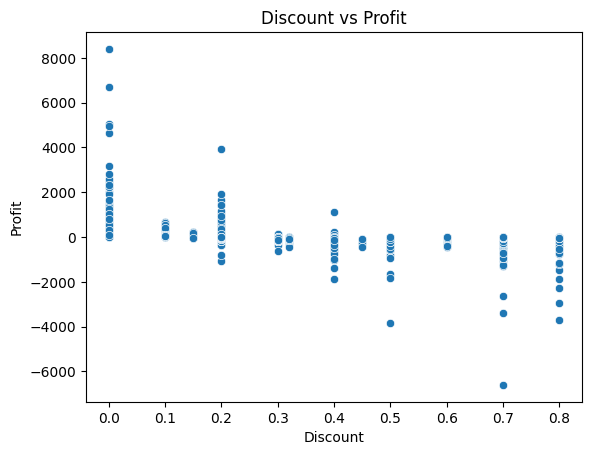

In [29]:
sns.scatterplot(data=df, x="Discount", y="Profit")

plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.show()

IndentationError: unexpected indent (3311151830.py, line 2)

In [31]:
import sqlite3



In [32]:
conn = sqlite3.connect("superstore.db")

In [33]:
df.to_sql("superstore", conn, if_exists="replace", index=False)

9994

In [34]:
query = """
SELECT
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit
FROM superstore;
"""

sql_result = pd.read_sql_query(query, conn)

sql_result


,Total_Sales,Total_Profit
0,2.297201e+06,286397.0217


In [35]:
query = """
SELECT
    Category,
    SUM(Sales) AS Total_Sales
FROM superstore
GROUP BY Category
ORDER BY Total_Sales DESC;
"""

category_sql = pd.read_sql_query(query, conn)

category_sql

,Category,Total_Sales
0,Technology,836154.0330
1,Furniture,741999.7953
2,Office Supplies,719047.0320


In [36]:
query = """
SELECT
    Region,
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY Region
ORDER BY Total_Sales DESC;
"""

region_sql = pd.read_sql_query(query, conn)

region_sql

,Region,Total_Sales,Total_Profit
0,West,725457.8245,108418.4489
1,East,678781.2400,91522.7800
2,Central,501239.8908,39706.3625
3,South,391721.9050,46749.4303


In [37]:
query = """
SELECT
    strftime('%Y-%m', "Order Date") AS Month,
    SUM(Sales) AS Total_Sales
FROM superstore
GROUP BY Month
ORDER BY Month;
"""

monthly_sql = pd.read_sql_query(query, conn)

monthly_sql

,Month,Total_Sales
0,2014-01,14236.8950
1,2014-02,4519.8920
2,2014-03,55691.0090
3,2014-04,28295.3450
4,2014-05,23648.2870
5,2014-06,34595.1276
6,2014-07,33946.3930
7,2014-08,27909.4685
8,2014-09,81777.3508
9,2014-10,31453.3930


In [38]:
query = """
SELECT
    "Product Name",
    SUM(Sales) AS Total_Sales
FROM superstore
GROUP BY "Product Name"
ORDER BY Total_Sales DESC
LIMIT 10;
"""

top_products_sql = pd.read_sql_query(query, conn)

top_products_sql

,Product Name,Total_Sales
0,Canon imageCLASS 2200 Advanced Copier,61599.824
1,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384
2,Cisco TelePresence System EX90 Videoconferenci...,22638.480
3,HON 5400 Series Task Chairs for Big and Tall,21870.576
4,GBC DocuBind TL300 Electric Binding System,19823.479
5,GBC Ibimaster 500 Manual ProClick Binding System,19024.500
6,Hewlett Packard LaserJet 3310 Copier,18839.686
7,HP Designjet T520 Inkjet Large Format Printer ...,18374.895
8,GBC DocuBind P400 Electric Binding System,17965.068
9,High Speed Automatic Electric Letter Opener,17030.312


In [39]:
query = """
SELECT
    "Customer Name",
    SUM(Sales) AS Total_Sales
FROM superstore
GROUP BY "Customer Name"
ORDER BY Total_Sales DESC
LIMIT 10;
"""

top_customers_sql = pd.read_sql_query(query, conn)

top_customers_sql

,Customer Name,Total_Sales
0,Sean Miller,25043.050
1,Tamara Chand,19052.218
2,Raymond Buch,15117.339
3,Tom Ashbrook,14595.620
4,Adrian Barton,14473.571
5,Ken Lonsdale,14175.229
6,Sanjit Chand,14142.334
7,Hunter Lopez,12873.298
8,Sanjit Engle,12209.438
9,Christopher Conant,12129.072


In [40]:
query = """
SELECT
    Category,
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY Category
ORDER BY Total_Profit DESC;
"""

category_performance_sql = pd.read_sql_query(query, conn)

category_performance_sql

,Category,Total_Sales,Total_Profit
0,Technology,836154.0330,145454.9481
1,Office Supplies,719047.0320,122490.8008
2,Furniture,741999.7953,18451.2728


In [41]:
query = """
SELECT
    "Order ID",
    "Product Name",
    Sales,
    Discount,
    Profit
FROM superstore
WHERE Profit < 0
ORDER BY Profit ASC
LIMIT 10;
"""

loss_orders = pd.read_sql_query(query, conn)

loss_orders

,Order ID,Product Name,Sales,Discount,Profit
0,CA-2016-108196,Cubify CubeX 3D Printer Double Head Print,4499.985,0.7,-6599.9780
1,US-2017-168116,Cubify CubeX 3D Printer Triple Head Print,7999.980,0.5,-3839.9904
2,CA-2014-169019,GBC DocuBind P400 Electric Binding System,2177.584,0.8,-3701.8928
3,CA-2017-134845,Lexmark MX611dhe Monochrome Laser Printer,2549.985,0.7,-3399.9800
4,US-2017-122714,Ibico EPK-21 Electric Binding System,1889.990,0.8,-2929.4845
5,CA-2015-147830,Cubify CubeX 3D Printer Double Head Print,1799.994,0.7,-2639.9912
6,CA-2017-131254,Fellowes PB500 Electric Punch Plastic Comb Bin...,1525.188,0.8,-2287.7820
7,CA-2015-116638,Chromcraft Bull-Nose Wood Oval Conference Tabl...,4297.644,0.4,-1862.3124
8,CA-2016-130946,GBC DocuBind P400 Electric Binding System,1088.792,0.8,-1850.9464
9,CA-2014-145317,Cisco TelePresence System EX90 Videoconferenci...,22638.480,0.5,-1811.0784


In [42]:
query = """
SELECT
    Discount,
    AVG(Profit) AS Average_Profit
FROM superstore
GROUP BY Discount
ORDER BY Discount;
"""

discount_profit_sql = pd.read_sql_query(query, conn)

discount_profit_sql

,Discount,Average_Profit
0,0.00,66.900292
1,0.10,96.055074
2,0.15,27.288298
3,0.20,24.702572
4,0.30,-45.679636
5,0.32,-88.560656
6,0.40,-111.927429
7,0.45,-226.646464
8,0.50,-310.703456
9,0.60,-43.077212


In [43]:
query = """
SELECT
    "Product Name",
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY "Product Name"
ORDER BY Total_Profit DESC
LIMIT 10;
"""

top_profit_products = pd.read_sql_query(query, conn)

top_profit_products

,Product Name,Total_Profit
0,Canon imageCLASS 2200 Advanced Copier,25199.9280
1,Fellowes PB500 Electric Punch Plastic Comb Bin...,7753.0390
2,Hewlett Packard LaserJet 3310 Copier,6983.8836
3,Canon PC1060 Personal Laser Copier,4570.9347
4,HP Designjet T520 Inkjet Large Format Printer ...,4094.9766
5,Ativa V4110MDD Micro-Cut Shredder,3772.9461
6,"3D Systems Cube Printer, 2nd Generation, Magenta",3717.9714
7,Plantronics Savi W720 Multi-Device Wireless He...,3696.2820
8,Ibico EPK-21 Electric Binding System,3345.2823
9,Zebra ZM400 Thermal Label Printer,3343.5360


In [44]:
query = """
SELECT
    Region,
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit,
    ROUND(SUM(Profit) * 100.0 / SUM(Sales), 2) AS Profit_Margin
FROM superstore
GROUP BY Region
ORDER BY Profit_Margin DESC;
"""

region_margin_sql = pd.read_sql_query(query, conn)

region_margin_sql

,Region,Total_Sales,Total_Profit,Profit_Margin
0,West,725457.8245,108418.4489,14.94
1,East,678781.2400,91522.7800,13.48
2,South,391721.9050,46749.4303,11.93
3,Central,501239.8908,39706.3625,7.92


In [84]:
query="""
select
   "Product Name",
   sum(Profit) as Total_Profit
   from superstore
   group by "Product Name"
   having sum(profit)<0
   order by total_profit ASC
   limit 10;
"""
lost_product_sql=pd.read_sql_query(query,conn)
lost_product_sql

,Product Name,Total_Profit
0,Cubify CubeX 3D Printer Double Head Print,-8879.9704
1,Lexmark MX611dhe Monochrome Laser Printer,-4589.9730
2,Cubify CubeX 3D Printer Triple Head Print,-3839.9904
3,Chromcraft Bull-Nose Wood Oval Conference Tabl...,-2876.1156
4,Bush Advantage Collection Racetrack Conference...,-1934.3976
5,GBC DocuBind P400 Electric Binding System,-1878.1662
6,Cisco TelePresence System EX90 Videoconferenci...,-1811.0784
7,Martin Yale Chadless Opener Electric Letter Op...,-1299.1836
8,Balt Solid Wood Round Tables,-1201.0581
9,BoxOffice By Design Rectangular and Half-Moon ...,-1148.4375


In [47]:
query = """
SELECT
    Category,
    ROUND(AVG(Sales), 2) AS Average_Sales,
    ROUND(AVG(Profit), 2) AS Average_Profit
FROM superstore
GROUP BY Category
ORDER BY Average_Profit DESC;
"""

category_average_sql = pd.read_sql_query(query, conn)

category_average_sql

,Category,Average_Sales,Average_Profit
0,Technology,452.71,78.75
1,Office Supplies,119.32,20.33
2,Furniture,349.83,8.70


In [48]:
query = """
SELECT
    Segment,
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY Segment
ORDER BY Total_Sales DESC;
"""

segment_sql = pd.read_sql_query(query, conn)

segment_sql

,Segment,Total_Sales,Total_Profit
0,Consumer,1.161401e+06,134119.2092
1,Corporate,7.061464e+05,91979.1340
2,Home Office,4.296531e+05,60298.6785


In [49]:
query = """
SELECT
    "Ship Mode",
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY "Ship Mode"
ORDER BY Total_Sales DESC;
"""

ship_mode_sql = pd.read_sql_query(query, conn)

ship_mode_sql

,Ship Mode,Total_Sales,Total_Profit
0,Standard Class,1.358216e+06,164088.7875
1,Second Class,4.591936e+05,57446.6354
2,First Class,3.514284e+05,48969.8399
3,Same Day,1.283631e+05,15891.7589


In [50]:
query = """
SELECT
    State,
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY State
ORDER BY Total_Sales DESC
LIMIT 10;
"""

top_states_sql = pd.read_sql_query(query, conn)

top_states_sql

,State,Total_Sales,Total_Profit
0,California,457687.6315,76381.3871
1,New York,310876.2710,74038.5486
2,Texas,170188.0458,-25729.3563
3,Washington,138641.2700,33402.6517
4,Pennsylvania,116511.9140,-15559.9603
5,Florida,89473.7080,-3399.3017
6,Illinois,80166.1010,-12607.8870
7,Ohio,78258.1360,-16971.3766
8,Michigan,76269.6140,24463.1876
9,Virginia,70636.7200,18597.9504


In [51]:
query = """
SELECT
    "Sub-Category",
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY "Sub-Category"
ORDER BY Total_Profit DESC;
"""

subcategory_sql = pd.read_sql_query(query, conn)

subcategory_sql

,Sub-Category,Total_Sales,Total_Profit
0,Copiers,149528.0300,55617.8249
1,Phones,330007.0540,44515.7306
2,Accessories,167380.3180,41936.6357
3,Paper,78479.2060,34053.5693
4,Binders,203412.7330,30221.7633
5,Chairs,328449.1030,26590.1663
6,Storage,223843.6080,21278.8264
7,Appliances,107532.1610,18138.0054
8,Furnishings,91705.1640,13059.1436
9,Envelopes,16476.4020,6964.1767


In [54]:
query = """
SELECT
    Segment,
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY Segment
ORDER BY Total_Profit DESC;
"""

segment_performance_sql = pd.read_sql_query(query, conn)

segment_performance_sql

,Segment,Total_Sales,Total_Profit
0,Consumer,1.161401e+06,134119.2092
1,Corporate,7.061464e+05,91979.1340
2,Home Office,4.296531e+05,60298.6785


In [56]:
query = """
SELECT
    "Ship Mode",
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY "Ship Mode"
ORDER BY Total_Profit DESC;
"""

ship_performance_sql = pd.read_sql_query(query, conn)

ship_performance_sql

,Ship Mode,Total_Sales,Total_Profit
0,Standard Class,1.358216e+06,164088.7875
1,Second Class,4.591936e+05,57446.6354
2,First Class,3.514284e+05,48969.8399
3,Same Day,1.283631e+05,15891.7589


In [57]:
query = """
SELECT
    Region,
    ROUND(AVG(Sales), 2) AS Average_Sales,
    ROUND(AVG(Profit), 2) AS Average_Profit
FROM superstore
GROUP BY Region
ORDER BY Average_Profit DESC;
"""

region_average_sql = pd.read_sql_query(query, conn)

region_average_sql

,Region,Average_Sales,Average_Profit
0,West,226.49,33.85
1,East,238.34,32.14
2,South,241.80,28.86
3,Central,215.77,17.09


In [58]:
query = """
SELECT
    State,
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY State
ORDER BY Total_Profit DESC
LIMIT 10;
"""

state_profit_sql = pd.read_sql_query(query, conn)

state_profit_sql

,State,Total_Sales,Total_Profit
0,California,457687.6315,76381.3871
1,New York,310876.2710,74038.5486
2,Washington,138641.2700,33402.6517
3,Michigan,76269.6140,24463.1876
4,Virginia,70636.7200,18597.9504
5,Indiana,53555.3600,18382.9363
6,Georgia,49095.8400,16250.0433
7,Kentucky,36591.7500,11199.6966
8,Minnesota,29863.1500,10823.1874
9,Delaware,27451.0690,9977.3748


In [59]:
query = """
SELECT
    Region,
    Category,
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY Region, Category
ORDER BY Region, Total_Profit DESC;
"""

region_category_sql = pd.read_sql_query(query, conn)

region_category_sql

,Region,Category,Total_Sales,Total_Profit
0,Central,Technology,170416.3120,33697.4320
1,Central,Office Supplies,167026.4150,8879.9799
2,Central,Furniture,163797.1638,-2871.0494
3,East,Technology,264973.9810,47462.0351
4,East,Office Supplies,205516.0550,41014.5791
5,East,Furniture,208291.2040,3046.1658
6,South,Technology,148771.9080,19991.8314
7,South,Office Supplies,125651.3130,19986.3928
8,South,Furniture,117298.6840,6771.2061
9,West,Office Supplies,220853.2490,52609.8490


In [60]:
query = """
SELECT
    "Customer Name",
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY "Customer Name"
ORDER BY Total_Profit DESC
LIMIT 10;
"""

top_profit_customers = pd.read_sql_query(query, conn)

top_profit_customers

,Customer Name,Total_Sales,Total_Profit
0,Tamara Chand,19052.218,8981.3239
1,Raymond Buch,15117.339,6976.0959
2,Sanjit Chand,14142.334,5757.4119
3,Hunter Lopez,12873.298,5622.4292
4,Adrian Barton,14473.571,5444.8055
5,Tom Ashbrook,14595.620,4703.7883
6,Christopher Martinez,8954.020,3899.8904
7,Keith Dawkins,8181.256,3038.6254
8,Andy Reiter,6608.448,2884.6208
9,Daniel Raglin,8350.868,2869.0760


In [61]:
query = """
SELECT
    Category,
    Segment,
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY Category, Segment
ORDER BY Category, Total_Profit DESC;
"""

category_segment_sql = pd.read_sql_query(query, conn)

category_segment_sql

,Category,Segment,Total_Sales,Total_Profit
0,Furniture,Corporate,229019.7858,7584.8158
1,Furniture,Consumer,391049.3120,6991.0786
2,Furniture,Home Office,121930.6975,3875.3784
3,Office Supplies,Consumer,363952.1360,56330.3210
4,Office Supplies,Corporate,230676.4620,40227.3202
5,Office Supplies,Home Office,124418.4340,25933.1596
6,Technology,Consumer,406399.8970,70797.8096
7,Technology,Corporate,246450.1190,44166.9980
8,Technology,Home Office,183304.0170,30490.1405


In [62]:
query = """
SELECT
    "Sub-Category",
    ROUND(AVG(Profit), 2) AS Average_Profit,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY "Sub-Category"
ORDER BY Average_Profit DESC;
"""

subcategory_profit_sql = pd.read_sql_query(query, conn)

subcategory_profit_sql

,Sub-Category,Average_Profit,Total_Profit
0,Copiers,817.91,55617.8249
1,Accessories,54.11,41936.6357
2,Phones,50.07,44515.7306
3,Chairs,43.10,26590.1663
4,Appliances,38.92,18138.0054
5,Machines,29.43,3384.7569
6,Envelopes,27.42,6964.1767
7,Storage,25.15,21278.8264
8,Paper,24.86,34053.5693
9,Binders,19.84,30221.7633


In [63]:
query = """
SELECT
    "Sub-Category",
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY "Sub-Category"
HAVING SUM(Profit) < 0
ORDER BY Total_Profit ASC;
"""

loss_subcategory_sql = pd.read_sql_query(query, conn)

loss_subcategory_sql

,Sub-Category,Total_Sales,Total_Profit
0,Tables,206965.5320,-17725.4811
1,Bookcases,114879.9963,-3472.5560
2,Supplies,46673.5380,-1189.0995


In [64]:
query = """
SELECT
    State,
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY State
ORDER BY Total_Sales DESC;
"""

state_performance_sql = pd.read_sql_query(query, conn)

state_performance_sql

,State,Total_Sales,Total_Profit
0,California,457687.6315,76381.3871
1,New York,310876.2710,74038.5486
2,Texas,170188.0458,-25729.3563
3,Washington,138641.2700,33402.6517
4,Pennsylvania,116511.9140,-15559.9603
5,Florida,89473.7080,-3399.3017
6,Illinois,80166.1010,-12607.8870
7,Ohio,78258.1360,-16971.3766
8,Michigan,76269.6140,24463.1876
9,Virginia,70636.7200,18597.9504


In [65]:
query = """
SELECT
    City,
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY City
ORDER BY Total_Sales DESC
LIMIT 10;
"""

top_cities_sql = pd.read_sql_query(query, conn)

top_cities_sql

,City,Total_Sales,Total_Profit
0,New York City,256368.1610,62036.9837
1,Los Angeles,175851.3410,30440.7579
2,Seattle,119540.7420,29156.0967
3,San Francisco,112669.0920,17507.3854
4,Philadelphia,109077.0130,-13837.7674
5,Houston,64504.7604,-10153.5485
6,Chicago,48539.5410,-6654.5688
7,San Diego,47521.0290,6377.1960
8,Jacksonville,44713.1830,-2323.8350
9,Springfield,43054.3420,6200.6974


In [66]:
query = """
SELECT
    City,
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY City
ORDER BY Total_Profit DESC
LIMIT 10;
"""

top_profit_cities_sql = pd.read_sql_query(query, conn)

top_profit_cities_sql

,City,Total_Sales,Total_Profit
0,New York City,256368.161,62036.9837
1,Los Angeles,175851.341,30440.7579
2,Seattle,119540.742,29156.0967
3,San Francisco,112669.092,17507.3854
4,Detroit,42446.944,13181.7908
5,Lafayette,25036.200,10018.3876
6,Jackson,24963.858,7581.6828
7,Atlanta,17197.840,6993.6629
8,Minneapolis,16870.540,6824.5846
9,San Diego,47521.029,6377.1960


In [67]:
query = """
SELECT
    strftime('%Y', "Order Date") AS Year,
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY Year
ORDER BY Year;
"""

yearly_performance_sql = pd.read_sql_query(query, conn)

yearly_performance_sql

,Year,Total_Sales,Total_Profit
0,2014,484247.4981,49543.9741
1,2015,470532.5090,61618.6037
2,2016,609205.5980,81795.1743
3,2017,733215.2552,93439.2696


In [68]:
query = """
SELECT
    strftime('%Y', "Order Date") AS Year,
    SUM(Sales) AS Total_Sales,
    SUM(Profit) AS Total_Profit,
    ROUND(SUM(Profit) * 100.0 / SUM(Sales), 2) AS Profit_Margin
FROM superstore
GROUP BY Year
ORDER BY Year;
"""

yearly_margin_sql = pd.read_sql_query(query, conn)

yearly_margin_sql

,Year,Total_Sales,Total_Profit,Profit_Margin
0,2014,484247.4981,49543.9741,10.23
1,2015,470532.5090,61618.6037,13.10
2,2016,609205.5980,81795.1743,13.43
3,2017,733215.2552,93439.2696,12.74


In [69]:
query = """
SELECT
    strftime('%Y', "Order Date") AS Year,
    SUM(Sales) AS Total_Sales
FROM superstore
GROUP BY Year
ORDER BY Year;
"""

yearly_sales_sql = pd.read_sql_query(query, conn)

yearly_sales_sql

,Year,Total_Sales
0,2014,484247.4981
1,2015,470532.5090
2,2016,609205.5980
3,2017,733215.2552


In [70]:
query = """
SELECT
    strftime('%Y', "Order Date") AS Year,
    COUNT(DISTINCT "Order ID") AS Total_Orders
FROM superstore
GROUP BY Year
ORDER BY Year;
"""

yearly_orders_sql = pd.read_sql_query(query, conn)

yearly_orders_sql

,Year,Total_Orders
0,2014,969
1,2015,1038
2,2016,1315
3,2017,1687


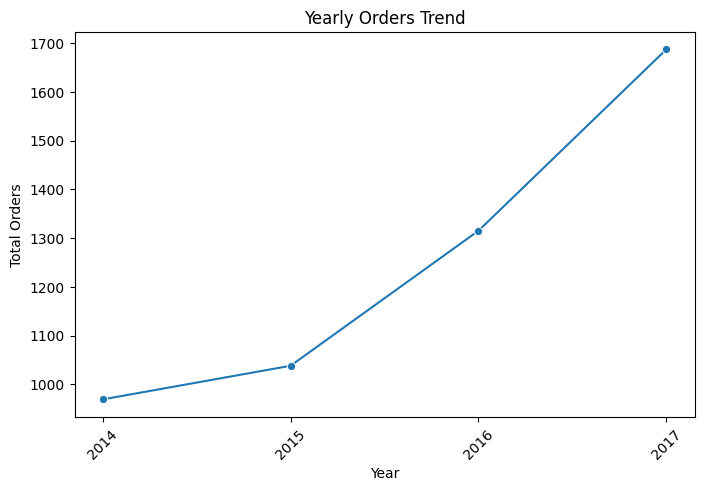

In [71]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    data=yearly_orders_sql,
    x="Year",
    y="Total_Orders",
    marker="o"
)

plt.title("Yearly Orders Trend")
plt.xlabel("Year")
plt.ylabel("Total Orders")
plt.xticks(rotation=45)
plt.show()

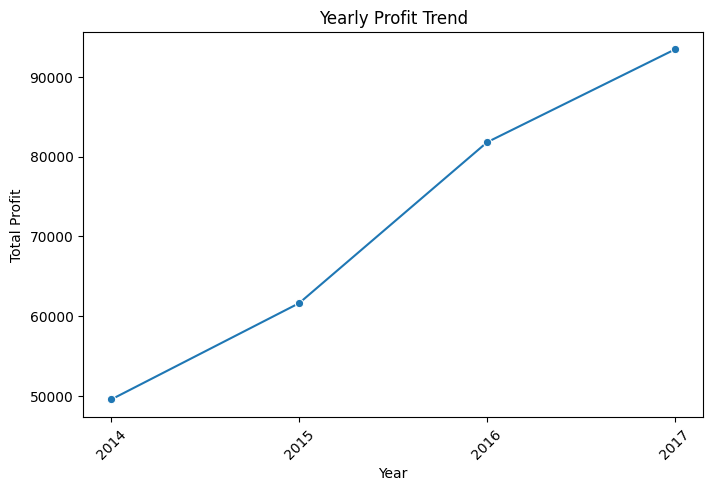

In [72]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    data=yearly_performance_sql,
    x="Year",
    y="Total_Profit",
    marker="o"
)

plt.title("Yearly Profit Trend")
plt.xlabel("Year")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.show()

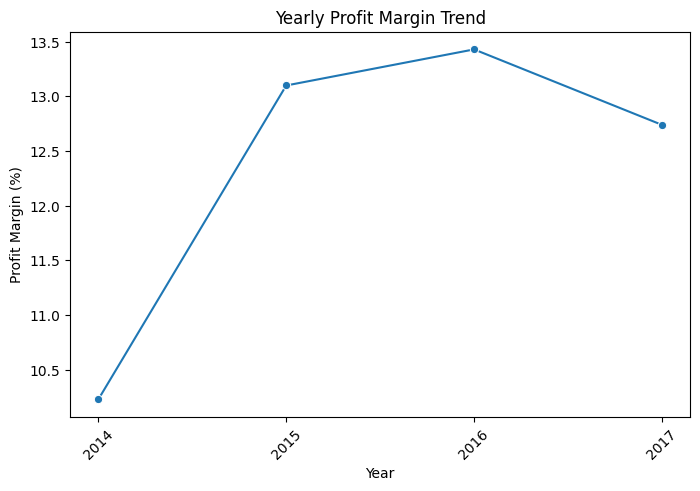

In [73]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    data=yearly_margin_sql,
    x="Year",
    y="Profit_Margin",
    marker="o"
)

plt.title("Yearly Profit Margin Trend")
plt.xlabel("Year")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=45)
plt.show()

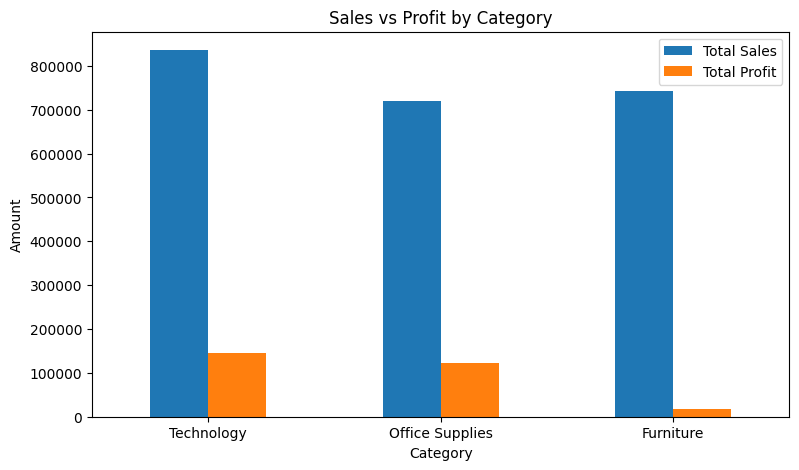

In [74]:
category_plot = category_performance_sql.set_index("Category")[["Total_Sales", "Total_Profit"]]

category_plot.plot(kind="bar", figsize=(9, 5))

plt.title("Sales vs Profit by Category")
plt.xlabel("Category")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.legend(["Total Sales", "Total Profit"])
plt.show()

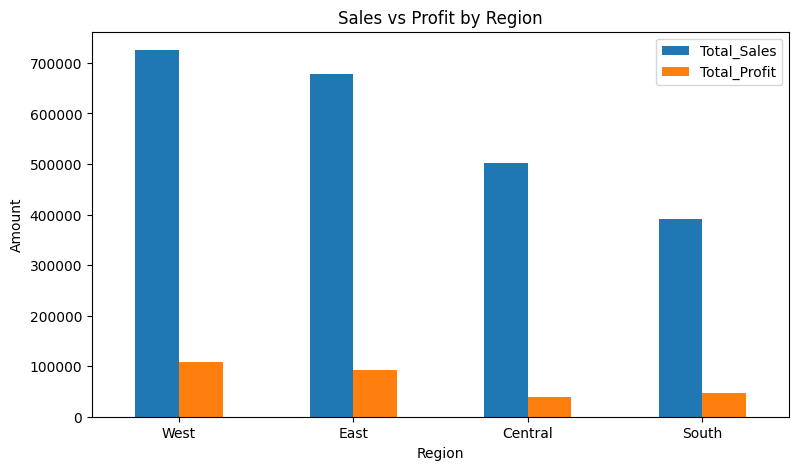

In [75]:
region_plot = region_sql.set_index("Region")[["Total_Sales", "Total_Profit"]]

region_plot.plot(kind="bar", figsize=(9, 5))

plt.title("Sales vs Profit by Region")
plt.xlabel("Region")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.legend()
plt.show()

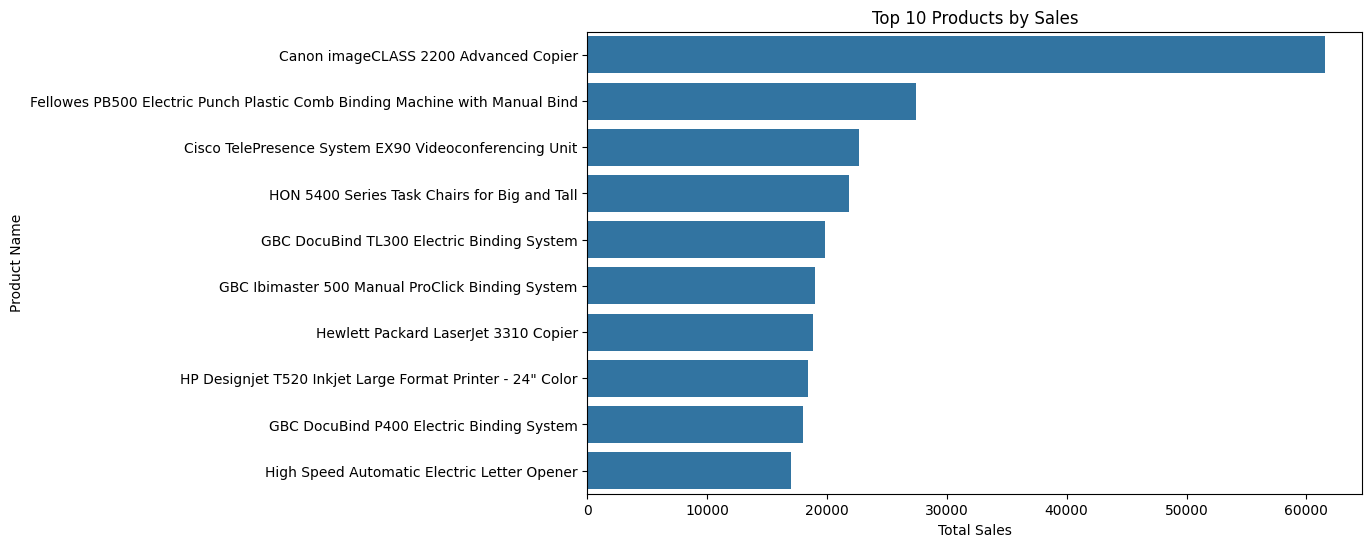

In [76]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_products_sql,
    x="Total_Sales",
    y="Product Name"
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")
plt.show()

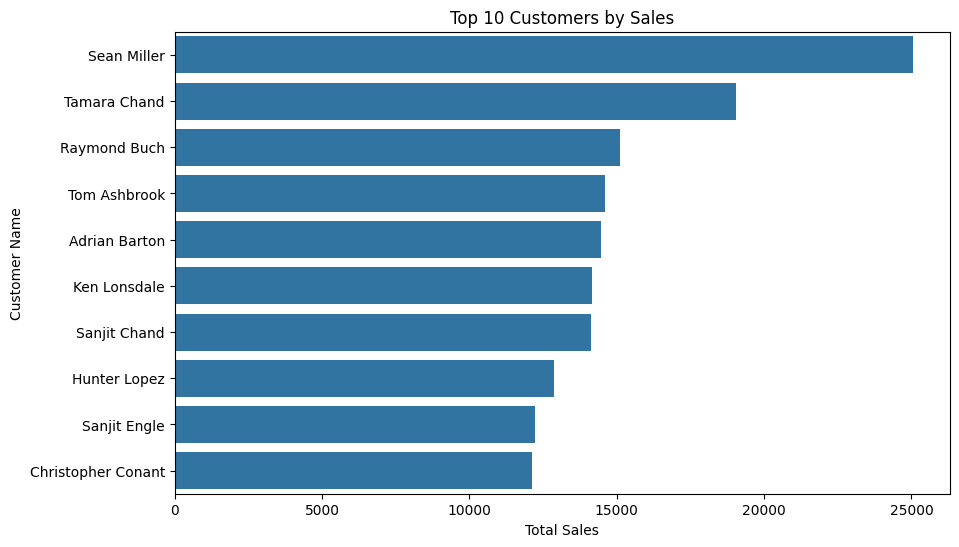

In [77]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_customers_sql,
    x="Total_Sales",
    y="Customer Name"
)

plt.title("Top 10 Customers by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer Name")
plt.show()

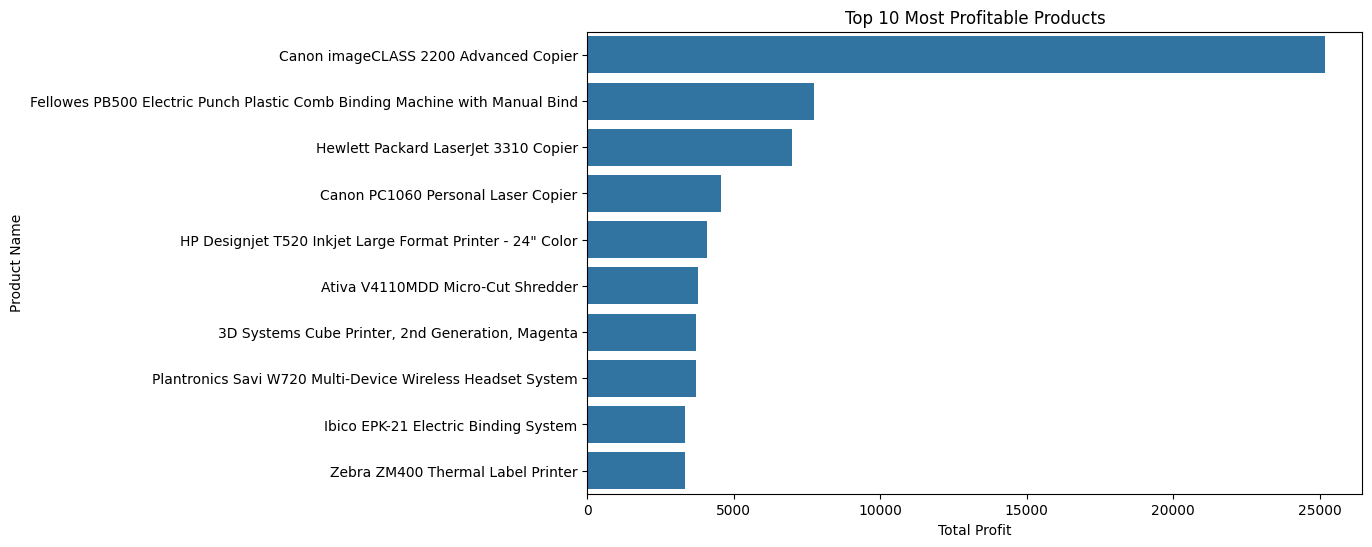

In [78]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_profit_products,
    x="Total_Profit",
    y="Product Name"
)

plt.title("Top 10 Most Profitable Products")
plt.xlabel("Total Profit")
plt.ylabel("Product Name")
plt.show()

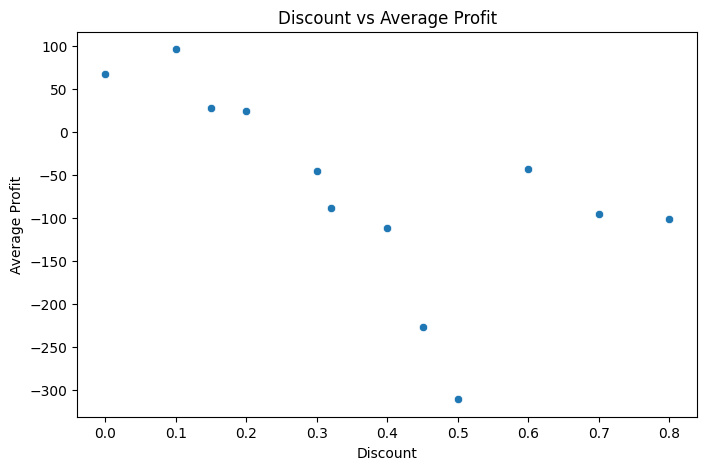

In [79]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=discount_profit_sql,
    x="Discount",
    y="Average_Profit"
)

plt.title("Discount vs Average Profit")
plt.xlabel("Discount")
plt.ylabel("Average Profit")
plt.show()

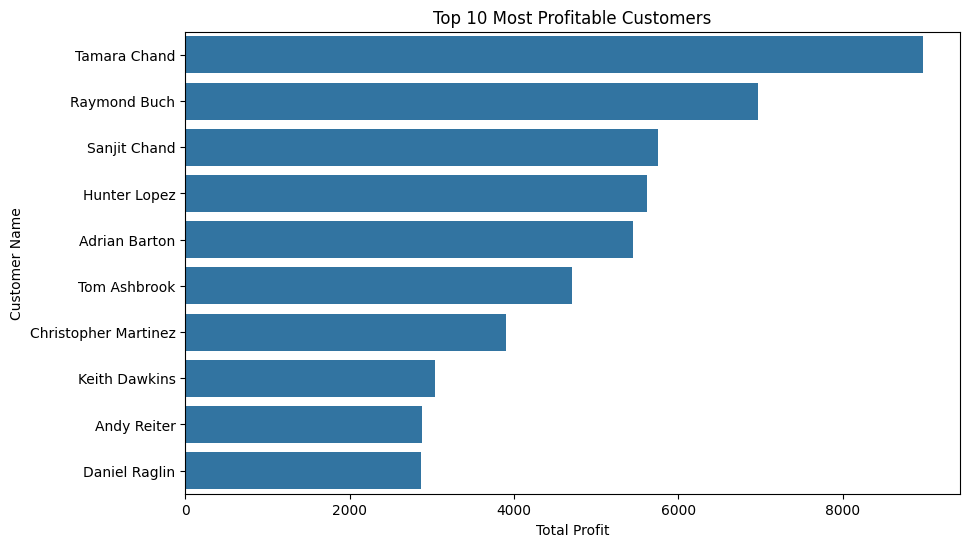

In [80]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_profit_customers,
    x="Total_Profit",
    y="Customer Name"
)

plt.title("Top 10 Most Profitable Customers")
plt.xlabel("Total Profit")
plt.ylabel("Customer Name")
plt.show()

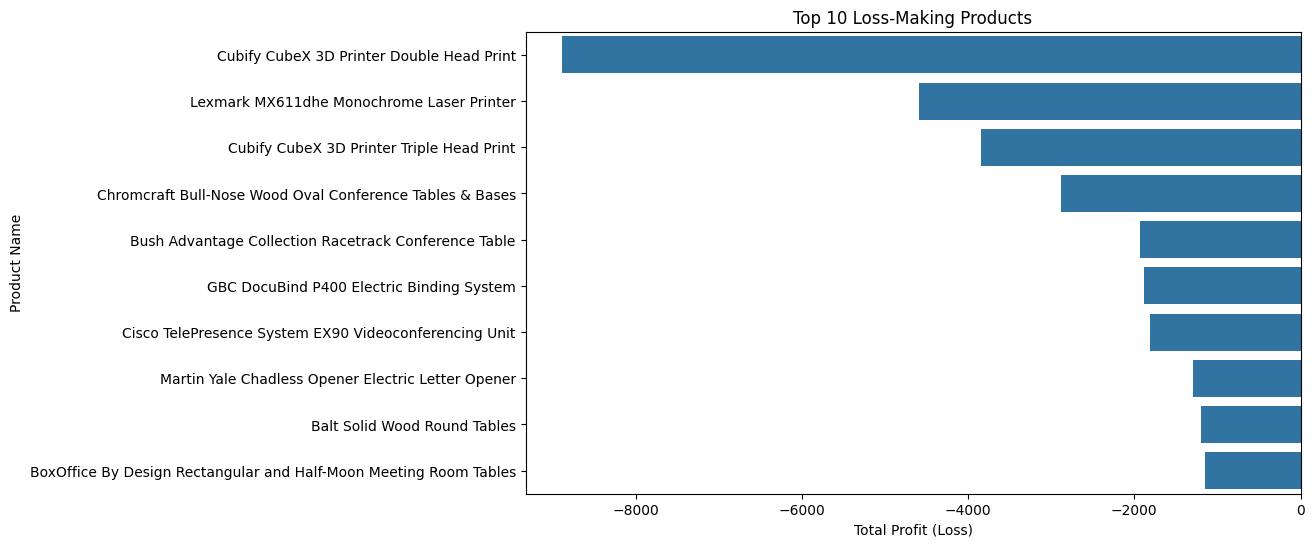

In [85]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=lost_product_sql,
    x="Total_Profit",
    y="Product Name"
)

plt.title("Top 10 Loss-Making Products")
plt.xlabel("Total Profit (Loss)")
plt.ylabel("Product Name")
plt.show()

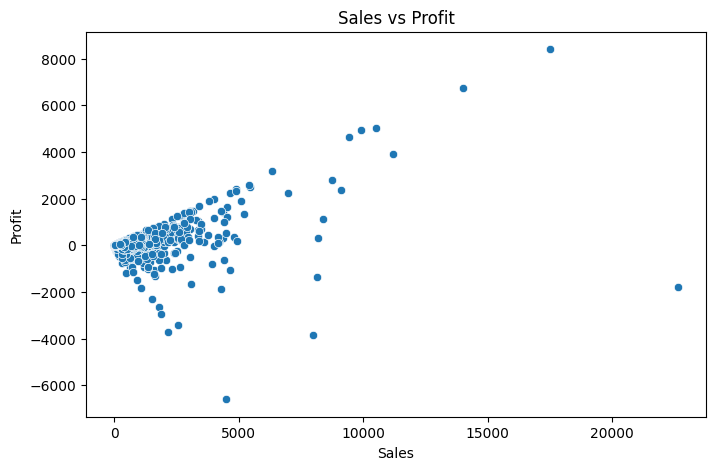

In [86]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Sales",
    y="Profit"
)

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.show()

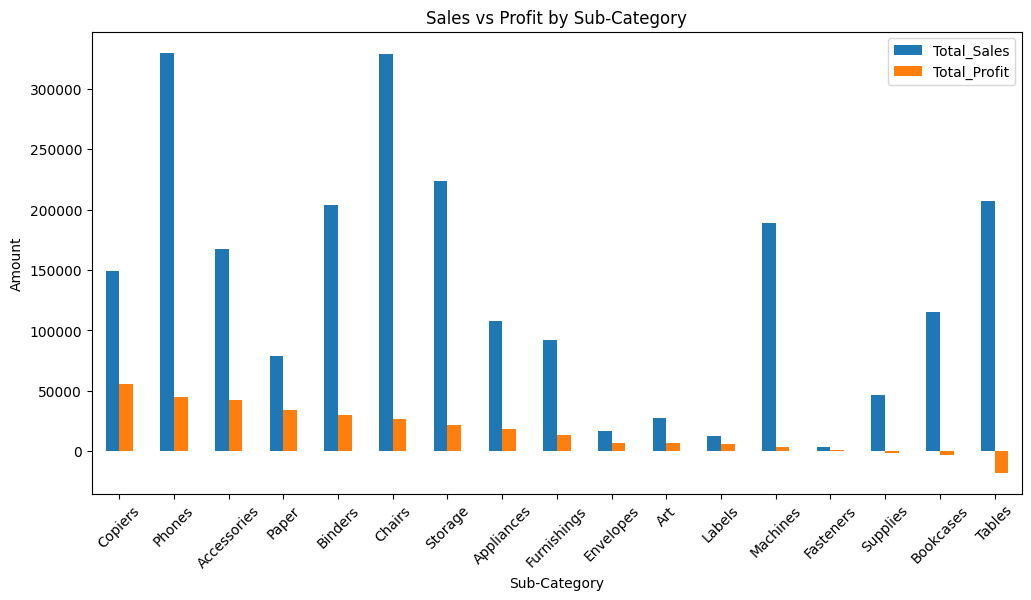

In [87]:
subcategory_plot = subcategory_sql.set_index("Sub-Category")[["Total_Sales", "Total_Profit"]]

subcategory_plot.plot(kind="bar", figsize=(12, 6))

plt.title("Sales vs Profit by Sub-Category")
plt.xlabel("Sub-Category")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.legend()
plt.show()

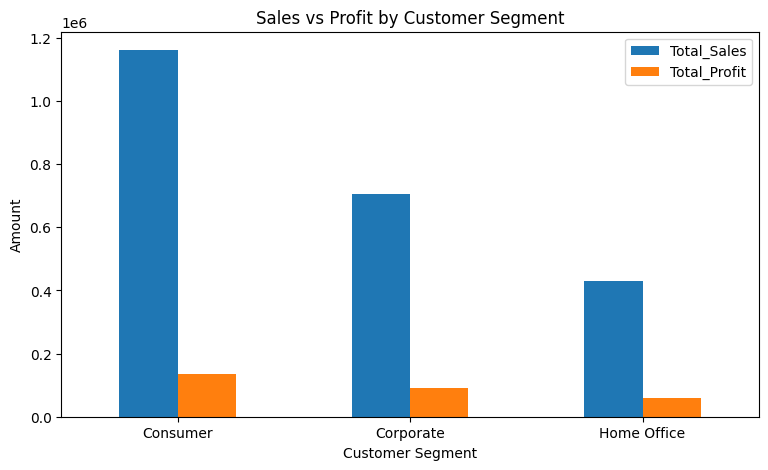

In [88]:
segment_plot = segment_performance_sql.set_index("Segment")[["Total_Sales", "Total_Profit"]]

segment_plot.plot(kind="bar", figsize=(9, 5))

plt.title("Sales vs Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.legend()
plt.show()

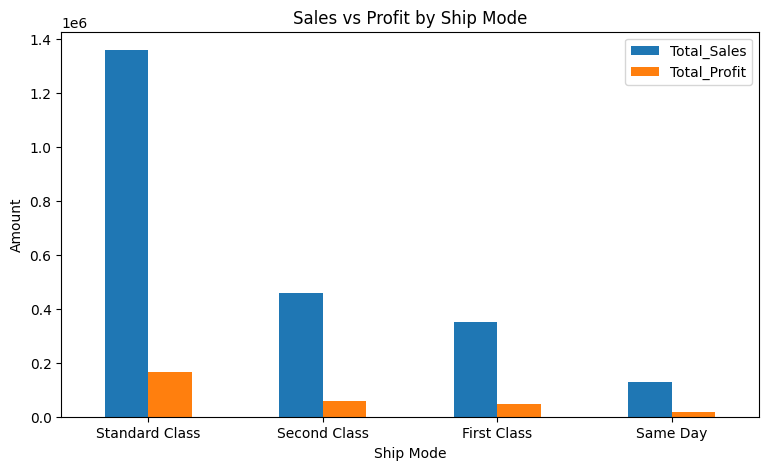

In [89]:
ship_plot = ship_performance_sql.set_index("Ship Mode")[["Total_Sales", "Total_Profit"]]

ship_plot.plot(kind="bar", figsize=(9, 5))

plt.title("Sales vs Profit by Ship Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.legend()
plt.show()

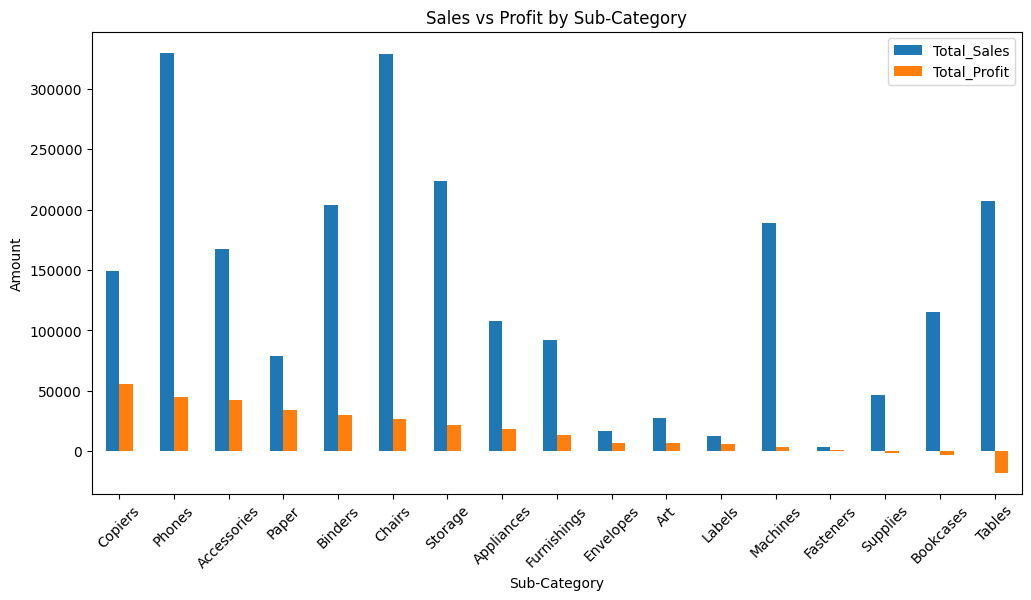

In [90]:
subcategory_plot = subcategory_sql.set_index("Sub-Category")[[
    "Total_Sales",
    "Total_Profit"
]]

subcategory_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Sales vs Profit by Sub-Category")
plt.xlabel("Sub-Category")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.legend()
plt.show()

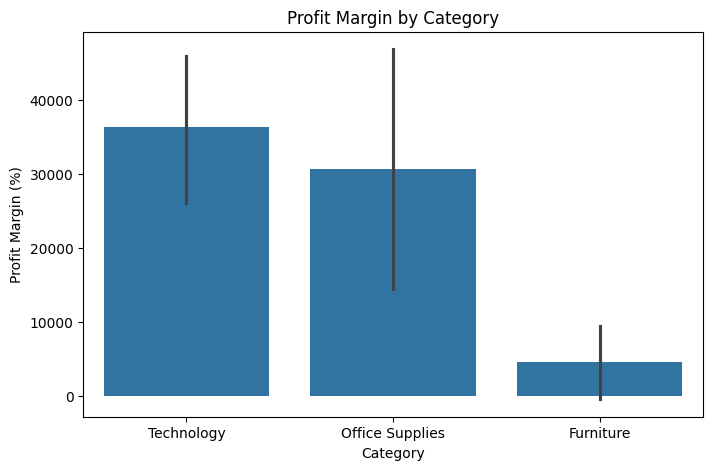

In [93]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=region_category_sql,
    x="Category",
    y="Total_Profit"
)

plt.title("Profit Margin by Category")
plt.xlabel("Category")
plt.ylabel("Profit Margin (%)")
plt.show()

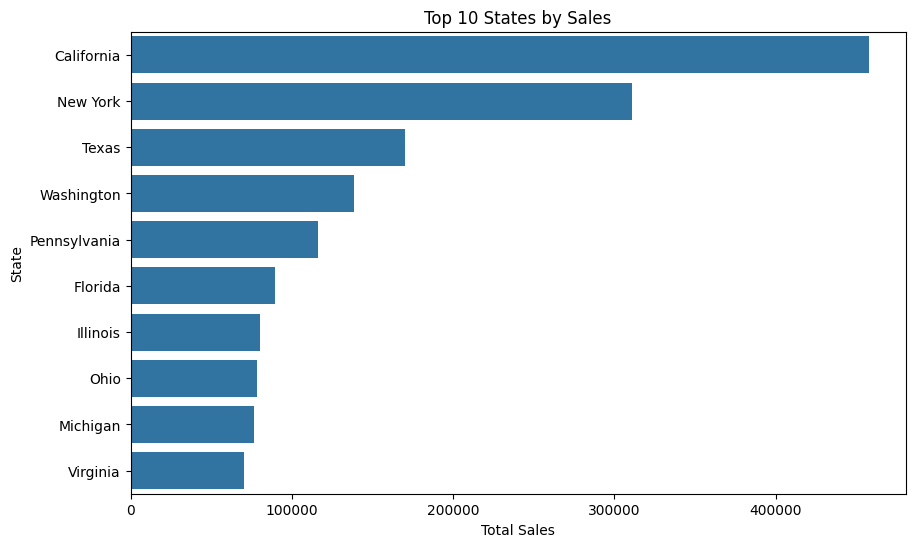

In [94]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_states_sql,
    x="Total_Sales",
    y="State"
)

plt.title("Top 10 States by Sales")
plt.xlabel("Total Sales")
plt.ylabel("State")
plt.show()

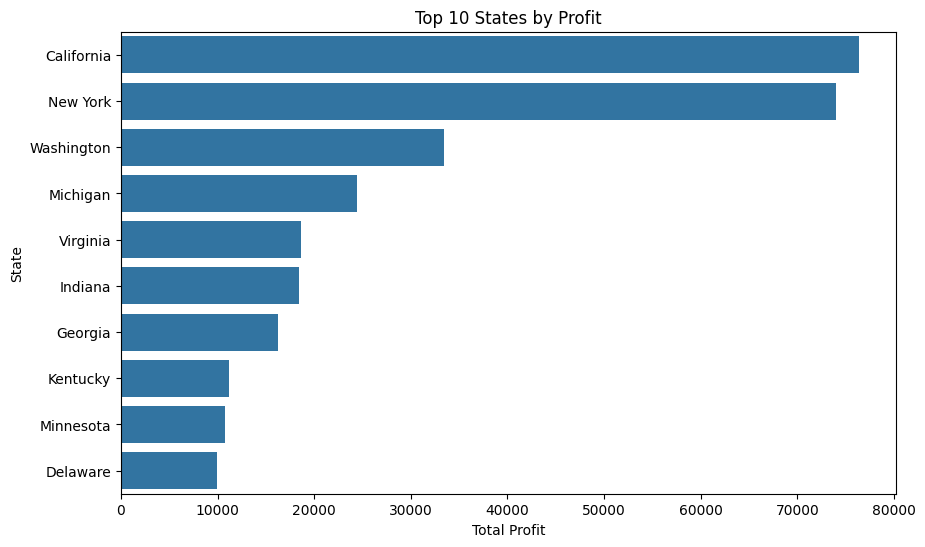

In [95]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=state_profit_sql,
    x="Total_Profit",
    y="State"
)

plt.title("Top 10 States by Profit")
plt.xlabel("Total Profit")
plt.ylabel("State")
plt.show()

In [96]:
print("Total Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))
print("Total Orders:", df["Order ID"].nunique())
print("Total Customers:", df["Customer Name"].nunique())

Total Sales: 2297200.86
Total Profit: 286397.02
Total Orders: 5009
Total Customers: 793


In [97]:
best_sales_category = category_sql.iloc[0]

print("Best-Selling Category:", best_sales_category["Category"])
print("Total Sales:", round(best_sales_category["Total_Sales"], 2))

Best-Selling Category: Technology
Total Sales: 836154.03


In [99]:
query = """
SELECT
    Category,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY Category
ORDER BY Total_Profit DESC;
"""

profit_category_sql = pd.read_sql_query(query, conn)

best_profit_category = profit_category_sql.iloc[0]

print("Most Profitable Category:", best_profit_category["Category"])
print("Total Profit:", round(best_profit_category["Total_Profit"], 2))

Most Profitable Category: Technology
Total Profit: 145454.95


In [100]:
best_sales_region = region_sql.iloc[0]

print("Best-Selling Region:", best_sales_region["Region"])
print("Total Sales:", round(best_sales_region["Total_Sales"], 2))

Best-Selling Region: West
Total Sales: 725457.82


In [102]:
query = """
SELECT
    Region,
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY Region
ORDER BY Total_Profit DESC;
"""

region_profit_sql = pd.read_sql_query(query, conn)

best_profit_region = region_profit_sql.iloc[0]

print("Most Profitable Region:", best_profit_region["Region"])
print("Total Profit:", round(best_profit_region["Total_Profit"], 2))

Most Profitable Region: West
Total Profit: 108418.45


In [103]:
query = """
SELECT
    "Sub-Category",
    SUM(Profit) AS Total_Profit
FROM superstore
GROUP BY "Sub-Category"
ORDER BY Total_Profit DESC
LIMIT 1;
"""

best_profit_subcategory = pd.read_sql_query(query, conn)

print("Most Profitable Sub-Category:", best_profit_subcategory.iloc[0]["Sub-Category"])
print("Total Profit:", round(best_profit_subcategory.iloc[0]["Total_Profit"], 2))

Most Profitable Sub-Category: Copiers
Total Profit: 55617.82


# Key Business Insights

- Analyzed overall sales and profit performance.
- Compared sales and profit across categories and regions.
- Identified top-performing products and customers.
- Analyzed yearly sales, orders, and profit trends.
- Studied the relationship between discounts and profit.
- Identified loss-making products and sub-categories.
- Analyzed customer segments and shipping methods.
- Calculated profit margins to understand business profitability.